# Scoring a unicycle trajectory with dynamics factors

A unicycle follows a discrete transition on `Pose2`. A factor graph assigns costs to its motion. We will assemble the joint graph, optimize the controls, and use the individual factors to account for the final cost. [Sampling planner walkthrough](../../../gtsam/planning/doc/SamplingPlanner.ipynb)

GTSAM Copyright 2010-2026, Georgia Tech Research Corporation,
Atlanta, Georgia 30332-0415

All Rights Reserved

Authors: Akash Ratheesh and Frank Dellaert (see THANKS for the full author list)

See LICENSE for the license information

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/borglab/gtsam/blob/develop/gtsam_unstable/planning/doc/MPPIWithDynamicsFactors.ipynb)

In [1]:
try:
    import google.colab
    %pip install --quiet gtsam-develop plotly==6.3.1
except ImportError:
    pass

In [2]:
from html import escape
import numpy as np
import gtsam
import gtsam_unstable as unstable
from gtsam.symbol_shorthand import U, X
import plotly.graph_objects as go
from IPython.display import HTML, display

teal, orange, slate = "#087B78", "#B65025", "#536577"
plotly_js = "https://cdn.plot.ly/plotly-3.1.1.min.js"

## Connect consecutive poses

There are $H$ controls and $H+1$ poses. The factor `UnicycleDynamicsFactor(X(k), U(k), X(k+1), model, hard)` measures the difference between the predicted and stored next poses. A robot that follows this exact transition has zero dynamics residual. Pose and control priors specify the cost of where the robot goes and how much it commands.

In [3]:
H, dt = 8, 0.2
state_keys = [gtsam.symbol("x", k) for k in range(H + 1)]
control_keys = [gtsam.symbol("u", k) for k in range(H)]
start, goal = gtsam.Pose2(), gtsam.Pose2(1.0, 0.4, 0.6)
model = unstable.Unicycle(dt)
hard = gtsam.noiseModel.Constrained.All(3)
running = gtsam.noiseModel.Diagonal.Precisions(np.array([1., 1., 0.1]))
terminal = gtsam.noiseModel.Diagonal.Precisions(np.array([40., 40., 5.]))
effort = gtsam.noiseModel.Isotropic.Precision(2, 0.2)

graph = gtsam.NonlinearFactorGraph()
terms = {"Dynamics": [], "Control effort": [], "Running pose": [], "Terminal pose": []}
for k, control_key in enumerate(control_keys):
    terms["Dynamics"].append(unstable.UnicycleDynamicsFactor(
        state_keys[k], control_key, state_keys[k + 1], model, hard))
    terms["Control effort"].append(gtsam.PriorFactorPoint2(control_key, np.zeros(2), effort))
    group, noise = ("Terminal pose", terminal) if k == H - 1 else ("Running pose", running)
    terms[group].append(gtsam.PriorFactorPose2(state_keys[k + 1], goal, noise))
for factors in terms.values():
    for factor in factors:
        graph.add(factor)

## Supply the same transition to the planner

The first rollout passes the model's Python prediction function through `discreteTransition`. The second uses the native `unicycleTransition(model)` adapter for the same discrete prediction. Both yield the same poses for nonzero commands. The native adapter keeps repeated predictions inside C++ during the optimization.

In [4]:
planner = gtsam.SamplingPlannerPose2Point2(state_keys, control_keys, dt)
seed = gtsam.Values()
seed.insert(X(0), start)
commands = np.tile(np.array([[0.6], [0.4]]), (1, H))
python_transition = gtsam.discreteTransition(model.predict)
dynamics = unstable.unicycleTransition(model)
reference = planner.rollout(seed, commands, python_transition)
native = planner.rollout(seed, commands, dynamics)
for key in state_keys:
    np.testing.assert_allclose(native.atPose2(key).localCoordinates(reference.atPose2(key)),
                               0.0, atol=1e-12)

## Optimize the controls

Each column of the nominal control matrix holds the forward speed and yaw rate for one interval. Starting from zero controls, MPPI scores 256 candidates in each of twelve iterations. The Gaussian proposal perturbs speed and yaw rate with standard deviations of 0.7 m/s and 0.5 rad/s. The returned `Values` contains the states and controls of the resulting trajectory.

In [5]:
initial = planner.rollout(seed, np.zeros((2, H)), dynamics)
proposal = gtsam.GaussianProposal(np.diag([0.7**2, 0.5**2]), 256, 42)
plan = planner.optimize(graph, initial, dynamics, proposal, gtsam.MPPI(1.0), 12)
print("First [speed, yaw rate]", plan.atPoint2(control_keys[0]))
print("Terminal pose", plan.atPose2(state_keys[-1]))

First [speed, yaw rate] [1.21837815 0.85130039]
Terminal pose (1.01426, 0.354342, 0.653365)



## Plan directly from a graph with dynamics factors

The joint graph contains enough information to reconstruct the transition at each control key. `VanillaMPPIControllerUnicycleDynamicsFactor` follows that chain and delegates the rollout and update to the sampling planner. Matching the covariance, sample count, inverse temperature, and seed lets us check the resulting controls against the explicit transition above.

In [6]:
params = gtsam.VanillaMPPIParams()
params.controlCovariance = np.diag([0.7**2, 0.5**2])
params.numSamples, params.iterations = 256, 12
params.inverseTemperature, params.seed = 1.0, 42
controller = unstable.VanillaMPPIControllerUnicycleDynamicsFactor(params)
factor_plan = controller.optimize(graph, initial, control_keys)
np.testing.assert_allclose(planner.nominalControls(factor_plan), planner.nominalControls(plan),
                           rtol=1e-10, atol=1e-12)

## Account for the objective

Summing the factor errors by group recovers the graph error. The dynamics residuals vanish for the two feasible rollouts. The remaining contributions show the cost of expending control effort to reduce running and terminal pose error. Interactive figures require an internet connection.

In [7]:
def costs_by_group(values):
    return np.array([sum(f.error(values) for f in group) for group in terms.values()])

before, after = costs_by_group(initial), costs_by_group(plan)
np.testing.assert_allclose([before.sum(), after.sum()], [graph.error(initial), graph.error(plan)])
np.testing.assert_allclose([before[0], after[0]], 0.0, atol=1e-12)
print(f"Total graph error {before.sum():.3f} → {after.sum():.3f}")

Total graph error 28.286 → 1.572


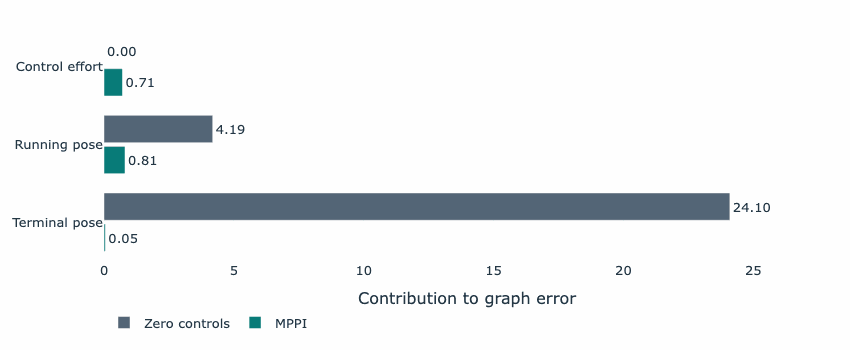

In [8]:
groups = list(terms)[1:]
fig = go.Figure()
for costs, label, color in [(before, "Zero controls", slate), (after, "MPPI", teal)]:
    fig.add_bar(x=costs[1:], y=groups, orientation="h", name=label, marker_color=color,
                text=[f"{value:.2f}" for value in costs[1:]], textposition="outside",
                cliponaxis=False, hovertemplate="%{y}<br>Cost %{x:.3f}<extra>%{fullData.name}</extra>")
fig.update_layout(barmode="group", bargroupgap=0.12)
fig.update_xaxes(title_text="Contribution to graph error", range=[0, 1.16 * max(before.max(), after.max())])
fig.update_yaxes(autorange="reversed", automargin=True)
fig.update_layout(template="plotly_white", height=350, margin=dict(l=63, r=20, t=28, b=65),
                  font=dict(size=13, color="#243744"), hoverlabel=dict(namelength=-1),
                  legend=dict(orientation="h", y=-0.20, x=0))
# Give Plotly its own document so the figure also runs in the published guide.
plot = fig.to_html(full_html=False, include_plotlyjs=plotly_js,
                   config={"displaylogo": False, "responsive": True})
document = '<!doctype html><meta charset="utf-8"><style>body{margin:0}</style>' + plot
display(HTML(f'<iframe title="Scoring a unicycle trajectory with dynamics factors" style="width:100%;border:0" '
             f'height="{fig.layout.height}" srcdoc="{escape(document, quote=True)}"></iframe>'))

Trajectory optimization uses the computed plan over its whole horizon. Receding-horizon control applies the first control and solves again after the next state measurement. [Unicycle trajectory optimization](../../../python/gtsam_unstable/examples/planning/UnicycleMPPITrajectoryOptimizationExample.ipynb) · [Unicycle MPC with process noise](../../../python/gtsam_unstable/examples/planning/UnicycleMPPIMPCExample.ipynb)